# A semi-multiplicative media mix model

Start with [Introduction to terms](introduction_terms.ipynb).
This example extends the [additive models](experimental_mmm_api.ipynb).
The model structure follows [issue #3088](https://github.com/pymc-labs/pymc-marketing/issues/3088).
Run the cells in order.

Media adds demand.
Price multiplies the total demand.
A Normal likelihood adds observation noise.

The introduction uses a linear price factor.
This example uses a power price factor.

We simulate weekly data with known parameters.
Then we fit the model, forecast sales, and optimize a media and price plan.
Each part uses the same terms.

> **Warning:** This API is experimental.
> Import it from `pymc_marketing.experimental.terms`.
> The stable `MMM` API does not change.

## 1. Set the units

Use two media channels.
Reserve 208 weeks for training.
Reserve the next 12 weeks for the forecast.

The simulation starts with no earlier spend.
Spend and price are independent inputs.

In [1]:
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
import numpy as np
import pandas as pd
import xarray as xr

rng = np.random.default_rng(sum(map(ord, "semi-multiplicative")))

In [3]:
n_train, n_forecast, l_max = 208, 12, 8
n_weeks = n_train + n_forecast
dates = pd.date_range("2020-01-06", periods=n_weeks, freq="W-MON")
channels = ["x1", "x2"]

Divide `x1` spend by 100.
Divide `x2` spend by 80.
Measure model sales in thousands.
Use a reference price of 10.

Keep these constants for training and forecasting.
Do not calculate them from future data.

In [4]:
channel_scale = xr.DataArray(
    [100.0, 80.0], dims="channel", coords={"channel": channels}
)
target_scale = 1_000.0
price_reference = 10.0

Set the known simulation parameters.
The baseline, media amplitudes, and noise use sales units.
The other parameters are dimensionless.

In [5]:
true_baseline, true_sigma = 1_000.0, 60.0
true_alpha = np.array([0.4, 0.2])
true_lam = np.array([3.0, 4.0])
true_beta = np.array([700.0, 400.0])
true_price_elasticity = -1.2

## 2. Simulate weekly data

Simulate spend and price independently.
Set some channel spend values to zero.

In [6]:
spend_scaled = rng.uniform(0.0, 1.0, size=(n_weeks, len(channels)))
spend_scaled *= rng.random(spend_scaled.shape) > 0.2
price = price_reference * rng.uniform(0.8, 1.2, size=n_weeks)

Calculate normalized geometric adstock with NumPy.
This calculation is independent of the fitted graph.
Each channel has eight lag weights that sum to one.

In [7]:
adstocked = np.empty_like(spend_scaled)
for c, alpha in enumerate(true_alpha):
    weights = alpha ** np.arange(l_max)
    weights /= weights.sum()
    adstocked[:, c] = np.convolve(spend_scaled[:, c], weights)[:n_weeks]

Apply logistic saturation to each channel.
Add the channel effects to the positive baseline.
These media effects use the reference price.

In [8]:
true_media_at_reference = true_beta * np.tanh(true_lam * adstocked / 2)
true_additive = true_baseline + true_media_at_reference.sum(axis=1)

Calculate the price multiplier.
Multiply the additive response by this multiplier.
Apply the same multiplier to each media effect.

In [9]:
true_multiplier = (price / price_reference) ** true_price_elasticity
true_response = true_additive * true_multiplier
true_media_contribution = true_media_at_reference * true_multiplier[:, None]

Add Normal observation noise.
The noise standard deviation is 60 sales units.

In [10]:
sales_noise = rng.normal(0.0, true_sigma, n_weeks)
observed_sales = true_response + sales_noise

Put the observations in a labeled dataset.
Keep this dataset in original units.

In [11]:
original = xr.Dataset(
    {
        "spend": (("date", "channel"), spend_scaled * channel_scale.values),
        "price": ("date", price),
        "sales": ("date", observed_sales),
    },
    coords={"date": dates, "channel": channels},
)

Apply the fixed scales.
Keep price in its original units.

In [12]:
scaled = original.assign(
    spend=original["spend"] / channel_scale,
    sales=original["sales"] / target_scale,
)

Separate the training data from the future inputs.
Do not give future sales to the model.

In [13]:
train = scaled.isel(date=slice(0, n_train))
future = scaled.isel(date=slice(n_train, None)).drop_vars("sales")
print(f"Training weeks: {train.sizes['date']}")
print(f"Forecast weeks: {future.sizes['date']}")

Training weeks: 208
Forecast weeks: 12


## 3. Write the model

The model adds media effects before it applies the price multiplier:

$$
A_t = b + \sum_c \beta_c f_c(x_{c,t}),\qquad
M_t = \left(\frac{p_t}{p_{\mathrm{ref}}}\right)^{\gamma_p}.
$$

The expected sales are $A_tM_t$.
The observations have additive Normal noise:

$$
y_t \sim \operatorname{Normal}(A_t M_t,\sigma).
$$

Here, $f_c$ applies normalized geometric adstock and logistic saturation.
A positive baseline and positive media amplitudes keep $A_t$ positive.
Price must also be positive.

At the reference price, $M_t=1$.
The mean then equals the additive response.
The Normal likelihood can give negative observations.

Name the two model inputs.
`Data` reads the dataset variable with the same name.
`sales` is the only observed target.

In [14]:
from pymc_marketing.experimental.terms import GAM, Data, Equation

spend_data = Data("spend")
price_data = Data("price")

Set the adstock prior.
The component uses a separate parameter for each channel.

In [15]:
from pymc_extras.prior import Prior

adstock_prior = Prior("Beta", alpha=2, beta=5)

Set the saturation priors.
`beta` is a positive amplitude in thousands of sales.
`lam` controls the saturation shape.

In [16]:
saturation_priors = {
    "beta": Prior("HalfNormal", sigma=0.8),
    "lam": Prior("Gamma", alpha=3, beta=1),
}

Configure the media components.
`GeometricAdstock` normalizes its lag weights by default.

In [17]:
from pymc_marketing.mmm import GeometricAdstock, LogisticSaturation

adstock = GeometricAdstock(l_max=l_max, priors={"alpha": adstock_prior})
saturation = LogisticSaturation(priors=saturation_priors)

Apply adstock before saturation.
Name the result `media_at_reference`.
It contains one media effect per channel at the reference price.

In [18]:
media_pipeline = spend_data >> adstock >> saturation
media_at_reference = media_pipeline.named("media_at_reference")

Make the positive baseline parameter.
Its Gamma prior uses thousands of sales.
`Parameter` gives the free variable the name `baseline`.

In [19]:
from pymc_marketing.terms import Parameter

baseline = Parameter("baseline", prior=Prior("Gamma", mu=1.0, sigma=0.5))

Sum the media effects over channels.
Add the baseline once per date.

In [20]:
media_total = media_at_reference.sum("channel")
additive = (baseline + media_total).named("additive_block")

Calculate the log price ratio.
`Transform` applies the named PyTensor operation to a term.

In [21]:
import pytensor.xtensor as ptx

from pymc_marketing.terms import Transform

price_ratio = price_data * (1.0 / price_reference)
price_log_ratio = Transform(price_ratio, func=ptx.math.log)

Set the price exponent prior.
The exponent is the conditional elasticity of expected sales at fixed spend.
It is dimensionless.

In [22]:
price_elasticity = Parameter("price_elasticity", prior=Prior("Normal", mu=0, sigma=1))

Multiply the log ratio by the exponent.
Then apply the exponential function in the next cell.
This gives $(p/p_{\mathrm{ref}})^{\gamma_p}$.

In [23]:
price_log_factor = (price_elasticity * price_log_ratio).named("price_log_factor")

In [24]:
market_multiplier = Transform(price_log_factor, func=ptx.math.exp).named(
    "market_multiplier"
)

Multiply the whole additive response by the price multiplier.
This term is the mean of the Normal likelihood.

In [25]:
sales_response = (additive * market_multiplier).named("sales_response")

Set the observation noise prior.
Keep the Normal likelihood separate from the mean.

In [26]:
noise_prior = Prior("HalfNormal", sigma=0.2)
likelihood = Prior("Normal", sigma=noise_prior)

Connect the mean to observed sales.
The equation name is `y`.
The dataset variable is `sales`.

In [27]:
sales = Equation(
    name="y",
    observed="sales",
    mu=sales_response,
    likelihood=likelihood,
)

Put the equation in a `GAM`.
The named intermediate terms are not additional observed targets.

In [28]:
gam = GAM(sales)

Build the graph with the training dataset.
`GAM` builds each term that the equation uses.

In [29]:
gam.build_model(train);

Show the model variables.
The price multiplier changes the mean, not the likelihood family.
No model-wide link setting is necessary.

In [30]:
from pymc_extras.printing import model_table

model_table(gam.model)

             Variable  Expression                                                           Dimensions             
───────────────────────────────────────────────────────────────────────────────────────────────────────────────────
              spend =  Data                                                                 date[208] × channel[2] 
              price =  Data                                                                 date[208]              
                                                                                                                   
           baseline ~  Gamma(<constant>, <constant>)                                                               
      adstock_alpha ~  Beta(2, 5)                                                           channel[2]             
     saturation_lam ~  Gamma(3, <constant>)                                                 channel[2]             
    saturation_beta ~  HalfNormal(0, 0.8)                                                   channel[2]             
   price_elasticity ~  Normal(0, 1)                                                                                
            y_sigma ~  HalfNormal(0, 0.2)                                                                          
                                                                                            Parameter count = 9    
                                                                                                                   
 media_at_reference =  f(saturation_beta, saturation_lam, adstock_alpha)                    date[208] × channel[2] 
     additive_block =  f(baseline, saturation_beta, saturation_lam, adstock_alpha)          date[208]              
   price_log_factor =  f(price_elasticity)                                                  date[208]              
  market_multiplier =  f(price_elasticity)                                                  date[208]              
     sales_response =  f(baseline, price_elasticity, saturation_beta, saturation_lam,       date[208]              
                       adstock_alpha)                                                                              
                                                                                                                   
                  y ~  Normal(f(baseline, price_elasticity, saturation_beta,                date[208]              
                       saturation_lam, adstock_alpha), y_sigma)

## 4. Compare the graph with NumPy

Substitute the known parameters before fitting.
Use the model scales for the baseline and media amplitudes.
The baseline substitution key is `baseline`.

In [31]:
truth_parameters = {
    "baseline": true_baseline / target_scale,
    "adstock_alpha": ptx.as_xtensor(true_alpha, dims=("channel",)),
    "saturation_lam": ptx.as_xtensor(true_lam, dims=("channel",)),
    "saturation_beta": ptx.as_xtensor(true_beta / target_scale, dims=("channel",)),
    "price_elasticity": true_price_elasticity,
}

Evaluate the three named parts at these parameters.

In [32]:
import pymc as pm

truth_model = pm.do(gam.model, truth_parameters)
graph_names = ["additive_block", "market_multiplier", "sales_response"]
graph_values = pm.draw([truth_model[name] for name in graph_names], random_seed=42)
graph_additive, graph_multiplier, graph_response = graph_values

Compare the additive response, price multiplier, and expected sales with NumPy.
These assertions cover adstock normalization, saturation, scaling, and the price reference at the known parameters.

In [33]:
np.testing.assert_allclose(
    graph_additive * target_scale, true_additive[:n_train], rtol=1e-12
)
np.testing.assert_allclose(graph_multiplier, true_multiplier[:n_train], rtol=1e-12)

In [34]:
np.testing.assert_allclose(
    graph_response * target_scale, true_response[:n_train], rtol=1e-12
)
print("The graph matches NumPy at the known parameters.")

The graph matches NumPy at the known parameters.


## 5. Sample from the prior

Simulate sales before fitting.
These draws include observation noise.
The priors are broader than the known simulation values.

In [35]:
prior = gam.sample_prior_predictive(train, draws=500, var_names=["y"], random_seed=11)
prior_sales = prior["prior_predictive"]["y"] * target_scale

Sampling: [adstock_alpha, baseline, price_elasticity, saturation_beta, saturation_lam, y, y_sigma]


Compare the prior sales range with observed training sales.
The priors do not use the known parameters as fitted values.

In [36]:
quantiles = [0.03, 0.5, 0.97]
prior_quantiles = np.quantile(prior_sales.values, quantiles)
observed_quantiles = np.quantile(original["sales"][:n_train].values, quantiles)

In [37]:
prior_comparison = pd.DataFrame(
    {
        "Prior predictive sales": prior_quantiles,
        "Observed training sales": observed_quantiles,
    },
    index=["3%", "Median", "97%"],
)
prior_comparison.round(1)

,Prior predictive sales,Observed training sales
3%,502.3,1068.9
Median,1476.7,1606.8
97%,3202.2,2271.8


## 6. Fit the model

Fit all 208 training weeks with four chains.
The model does not use the 12 future sales values during fitting.

In [38]:
idata = gam.fit(
    train,
    chains=4,
    tune=1_500,
    draws=1_000,
    target_accept=0.95,
    nuts_sampler="nutpie",
    random_seed=21,
    progressbar=False,
)

NUTS[nutpie]: [baseline, adstock_alpha, saturation_lam, saturation_beta, price_elasticity, y_sigma]


### Read the sampling diagnostics

Select the baseline, media parameters, price elasticity, and noise.
Keep the individual R-hat and effective sample size values in the summary.

In [39]:
import arviz as az

media_parameter_names = ["adstock_alpha", "saturation_beta", "saturation_lam"]
parameter_names = ["baseline", *media_parameter_names, "price_elasticity", "y_sigma"]
parameter_summary = az.summary(idata, var_names=parameter_names, round_to=3)

In [40]:
posterior = idata["posterior"].to_dataset()
posterior_draws = posterior.sizes["chain"] * posterior.sizes["draw"]
divergences = int(idata["sample_stats"]["diverging"].sum())

In [41]:
diagnostics = pd.Series(
    {
        "Posterior draws": posterior_draws,
        "Divergences": divergences,
        "Maximum R-hat": parameter_summary["r_hat"].max(),
        "Minimum bulk ESS": parameter_summary["ess_bulk"].min(),
    },
    name="Sampling diagnostics",
)

Read the diagnostics from this run.
Good sampling diagnostics do not guarantee parameter identification.

In [42]:
from IPython.display import display

display(diagnostics.to_frame())
parameter_summary

,Sampling diagnostics
Posterior draws,4000.000
Divergences,0.000
Maximum R-hat,1.003
Minimum bulk ESS,1212.536


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
baseline,0.988,0.018,0.959,1.015,1668.949,1760.904,1.003,0.000,0.000
adstock_alpha[x1],0.395,0.016,0.369,0.420,2916.044,2699.092,1.000,0.000,0.000
adstock_alpha[x2],0.186,0.025,0.145,0.227,2657.220,2840.828,1.002,0.000,0.000
saturation_beta[x1],0.702,0.030,0.657,0.751,1233.783,1724.045,1.002,0.001,0.001
saturation_beta[x2],0.392,0.017,0.365,0.421,1991.142,2311.996,1.002,0.000,0.000
saturation_lam[x1],3.236,0.249,2.845,3.638,1212.536,1551.598,1.003,0.007,0.005
saturation_lam[x2],4.148,0.341,3.613,4.692,2063.959,2289.399,1.002,0.008,0.005
price_elasticity,-1.211,0.018,-1.240,-1.183,5089.092,2691.188,1.001,0.000,0.000
y_sigma,0.052,0.003,0.048,0.057,5578.700,3233.471,1.000,0.000,0.000


### Compare parameters with their known values

Convert the baseline, media amplitudes, and noise to sales units.
Keep the other parameter scales unchanged.

In [43]:
recovery_parameters = [
    ("baseline", true_baseline, target_scale),
    ("adstock_alpha", true_alpha, 1.0),
    ("saturation_beta", true_beta, target_scale),
    ("saturation_lam", true_lam, 1.0),
    ("price_elasticity", true_price_elasticity, 1.0),
    ("y_sigma", true_sigma, target_scale),
]

Keep each channel parameter under its own label.
Keep the corresponding known value under the same label.

In [44]:
recovery_samples = {}
recovery_truth = {}

In [45]:
for name, truth, scale in recovery_parameters:
    values = posterior[name] * scale
    if "channel" in values.dims:
        for i, channel in enumerate(channels):
            label = f"{name}[{channel}]"
            recovery_samples[label] = values.sel(channel=channel).values.ravel()
            recovery_truth[label] = truth[i]
    else:
        recovery_samples[name] = values.values.ravel()
        recovery_truth[name] = truth

Calculate the posterior means and equal-tailed 94% intervals.
These intervals describe posterior uncertainty, not Monte Carlo error.

In [46]:
recovery_frame = pd.DataFrame(recovery_samples)
recovery = pd.DataFrame(
    {
        "Known value": recovery_truth,
        "Posterior mean": recovery_frame.mean(),
        "3%": recovery_frame.quantile(0.03),
        "97%": recovery_frame.quantile(0.97),
    }
)

In [47]:
recovery.index.name = "Parameter"
recovery.round(3)

,Known value,Posterior mean,3%,97%
Parameter,,,,
baseline,1000.0,987.538,953.712,1020.519
adstock_alpha[x1],0.4,0.395,0.364,0.425
adstock_alpha[x2],0.2,0.186,0.138,0.234
saturation_beta[x1],700.0,702.305,649.667,762.243
saturation_beta[x2],400.0,392.001,360.890,426.062
saturation_lam[x1],3.0,3.236,2.769,3.705
saturation_lam[x2],4.0,4.148,3.527,4.802
price_elasticity,-1.2,-1.211,-1.245,-1.178
y_sigma,60.0,52.261,47.599,57.423


Read the recovery table from this run.
A close sales fit does not guarantee precise parameter recovery.
Saturation amplitude and shape can compensate for each other.

Compare the recovered media effects in the next step.

## 7. Compare fitted sales and media effects

Predict the training dates without earlier history.
The simulation also starts without earlier spend.
Training-end history would be incorrect for this prediction.

In [48]:
prediction_names = [
    "y",
    "sales_response",
    "media_at_reference",
    "market_multiplier",
    "additive_block",
    "baseline",
]

In [49]:
in_sample = gam.sample_posterior_predictive(
    train,
    var_names=prediction_names,
    include_last_observations=False,
    random_seed=31,
    progressbar=False,
)

Sampling: [y]


Prepare the plots.
Build each plot in small steps.
Close each new figure to stop Jupyter from showing an incomplete plot.
Show the figure after its final step.

In [50]:
import matplotlib.pyplot as plt

az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [10, 4]
plt.rcParams["figure.dpi"] = 70

Calculate the 94% predictive highest-density interval.
The interval includes observation noise.
The model does not use the known expected sales as observations.

In [51]:
predicted_sales = in_sample["y"] * target_scale
sales_interval = az.hdi(predicted_sales, prob=0.94)
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
plt.close(fig)

In [52]:
ax.fill_between(
    train["date"],
    sales_interval.sel(ci_bound="lower"),
    sales_interval.sel(ci_bound="upper"),
    alpha=0.3,
    label="94% predictive HDI",
);

Add the observed training sales.

In [53]:
ax.plot(
    train["date"],
    original["sales"][:n_train],
    color="black",
    alpha=0.5,
    label="Observed sales",
);

Add the known expected sales as a dashed line.

In [54]:
ax.plot(
    train["date"],
    true_response[:n_train],
    color="C1",
    linestyle="--",
    label="Known expected sales",
);

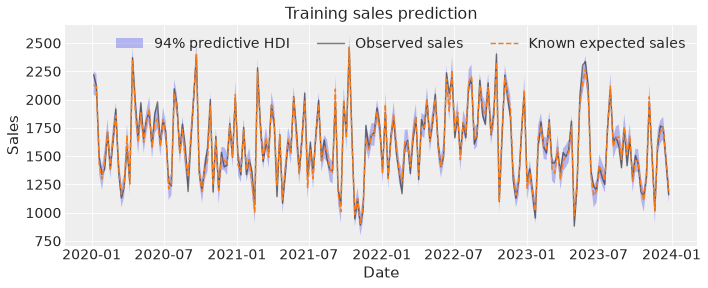

In [55]:
ax.set(title="Training sales prediction", xlabel="Date", ylabel="Sales")
ax.legend(ncol=3)
fig

### Reconcile the baseline and media effects

Removing channel $c$ changes expected sales by $\beta_cf_c(x_{c,t})M_t$.
The price multiplier does not depend on spend.

Multiply each reference media effect by the current multiplier before summing dates.
Apply the same multiplier to the baseline.

In [56]:
media_contribution = (
    in_sample["media_at_reference"] * in_sample["market_multiplier"] * target_scale
)
scaled_baseline = in_sample["baseline"] * in_sample["market_multiplier"] * target_scale

Make sure the scaled baseline and media sum to expected sales in each draw and week.
Do not add a separate price effect to this sum.
That would count the interactions twice.

In [57]:
np.testing.assert_allclose(
    scaled_baseline + media_contribution.sum("channel"),
    in_sample["sales_response"] * target_scale,
    rtol=1e-12,
)
print("The scaled baseline and media reconcile in each draw and week.")

The scaled baseline and media reconcile in each draw and week.


Calculate the 94% posterior interval for each media effect.
Keep the channel labels.

In [58]:
media_intervals = {}
for channel in channels:
    effect = media_contribution.sel(channel=channel)
    media_intervals[channel] = az.hdi(effect, prob=0.94)

In [59]:
fig, axes = plt.subplots(nrows=2, figsize=(10, 6), sharex=True, layout="constrained")
plt.close(fig)

Add the posterior interval to each channel plot.

In [60]:
for i, (channel, ax) in enumerate(zip(channels, axes, strict=True)):
    interval = media_intervals[channel]
    ax.fill_between(
        train["date"],
        interval.sel(ci_bound="lower"),
        interval.sel(ci_bound="upper"),
        color=f"C{i}",
        alpha=0.3,
        label="94% posterior HDI",
    )

Add the posterior mean media effects.

In [61]:
for i, (channel, ax) in enumerate(zip(channels, axes, strict=True)):
    effect_mean = media_contribution.sel(channel=channel).mean(("chain", "draw"))
    ax.plot(train["date"], effect_mean, color=f"C{i}", label="Posterior mean")

Add the known media effects as dashed lines.

In [62]:
for i, ax in enumerate(axes):
    ax.plot(
        train["date"],
        true_media_contribution[:n_train, i],
        color="black",
        linestyle="--",
        label="Known media effect",
    )

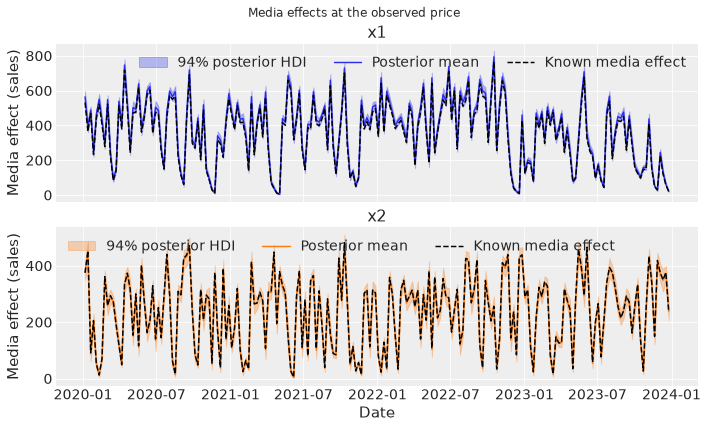

In [63]:
for channel, ax in zip(channels, axes, strict=True):
    ax.set(title=channel, ylabel="Media effect (sales)")
    ax.legend(ncol=3)
axes[-1].set_xlabel("Date")
fig.suptitle("Media effects at the observed price")
fig

### Use the reference price

Keep training spend unchanged.
Set each price to the reference price.
Do not prepend training history.

In [64]:
neutral_inputs = train.drop_vars("sales").assign(
    price=xr.full_like(train["price"], price_reference),
)

In [65]:
neutral = gam.sample_posterior_predictive(
    neutral_inputs,
    var_names=["market_multiplier", "additive_block", "sales_response"],
    include_last_observations=False,
    random_seed=41,
    progressbar=False,
)

Sampling: []


Make sure the multiplier equals one in each draw.
Make sure expected sales equal the additive response.

In [66]:
np.testing.assert_allclose(neutral["market_multiplier"], 1.0, atol=1e-12)
np.testing.assert_allclose(
    neutral["sales_response"], neutral["additive_block"], rtol=1e-12
)
print("At the reference price, expected sales equal the additive response.")

At the reference price, expected sales equal the additive response.


## 8. Forecast 12 weeks

The future dates immediately follow training.
Use the last seven training weeks as adstock history.
`include_last_observations=True` removes these history rows from the returned forecast.

Supply future spend and price explicitly.
Keep the scales, reference price, and posterior parameters unchanged.

In [67]:
forecast = gam.sample_posterior_predictive(
    future,
    var_names=["y", "sales_response"],
    include_last_observations=True,
    random_seed=51,
    progressbar=False,
)

Sampling: [y]


Lower each future price by 10%.
Keep spend and history unchanged.
Compare expected sales instead of independent noisy observations.

In [68]:
lower_price = gam.sample_posterior_predictive(
    future.assign(price=future["price"] * 0.9),
    var_names=["sales_response"],
    include_last_observations=True,
    random_seed=51,
    progressbar=False,
)

Sampling: []


Make sure the paired draws satisfy the elasticity identity:

$$
\frac{\mu_t(0.9p_t)}{\mu_t(p_t)}=0.9^{\gamma_p}.
$$

This also tests that the price scenario preserves media history, reference values, and posterior parameters.

In [69]:
paired_price_ratio = (0.9 ** posterior["price_elasticity"]).broadcast_like(
    forecast["sales_response"]
)
np.testing.assert_allclose(
    lower_price["sales_response"] / forecast["sales_response"],
    paired_price_ratio,
    rtol=1e-12,
)

Calculate the total expected sales gain for each paired draw.
Express the relative gain against the unchanged-price forecast.

In [70]:
scenario_gain = (lower_price["sales_response"] - forecast["sales_response"]).sum(
    "date"
) * target_scale
relative_gain = scenario_gain / (forecast["sales_response"].sum("date") * target_scale)
true_relative_gain = 0.9**true_price_elasticity - 1

Calculate forecast error against observed future sales.
Also calculate error against known expected sales.
The two errors use the posterior mean expected sales.

In [71]:
forecast_draws = forecast["y"] * target_scale
forecast_mean = forecast["sales_response"].mean(("chain", "draw")) * target_scale
held_out_sales = original["sales"][n_train:]
forecast_error = forecast_mean - held_out_sales
truth_error = forecast_mean - true_response[n_train:]

In [72]:
forecast_metrics = {
    "RMSE against observed future sales": float(np.sqrt((forecast_error**2).mean())),
    "RMSE against known expected sales": float(np.sqrt((truth_error**2).mean())),
    "Mean expected sales gain (%)": 100 * relative_gain.mean().item(),
}

Add the gain interval and probability.
Compare the posterior gain with the gain from the known elasticity.
The gain interval measures uncertainty in the elasticity.

In [73]:
forecast_metrics["Gain 3% (%)"] = 100 * np.quantile(relative_gain.values, 0.03)
forecast_metrics["Gain 97% (%)"] = 100 * np.quantile(relative_gain.values, 0.97)
forecast_metrics["P(expected sales gain > 0)"] = (scenario_gain > 0).mean().item()
forecast_metrics["Known expected sales gain (%)"] = 100 * true_relative_gain
pd.Series(forecast_metrics, name="Forecast and price scenario").to_frame().round(3)

,Forecast and price scenario
RMSE against observed future sales,46.277
RMSE against known expected sales,9.708
Mean expected sales gain (%),13.613
Gain 3% (%),13.216
Gain 97% (%),14.013
P(expected sales gain > 0),1.000
Known expected sales gain (%),13.477


Show the forecast interval and the gain distribution.
The forecast interval includes observation noise.
The gain distribution uses paired expected sales.

In [74]:
fig, axes = plt.subplots(ncols=2, figsize=(10, 4), layout="constrained")
plt.close(fig)
forecast_interval = az.hdi(forecast_draws, prob=0.94)

In [75]:
axes[0].fill_between(
    future["date"],
    forecast_interval.sel(ci_bound="lower"),
    forecast_interval.sel(ci_bound="upper"),
    alpha=0.3,
    label="94% predictive HDI",
);

Add the forecast mean and observed future sales.

In [76]:
axes[0].plot(future["date"], forecast_mean, label="Forecast mean")
axes[0].plot(future["date"], held_out_sales, "ko", label="Observed future sales");

Add the known expected sales as a dashed line.

In [77]:
axes[0].plot(
    future["date"],
    true_response[n_train:],
    linestyle="--",
    color="C1",
    label="Known expected sales",
);

In [78]:
axes[0].set(title="12-week sales forecast", xlabel="Date", ylabel="Sales")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=8);

Show the paired gain distribution as a percentage.
Mark the gain from the known price elasticity.

In [79]:
axes[1].hist(100 * relative_gain.values.ravel(), bins=40, density=True, alpha=0.7)
axes[1].axvline(
    100 * true_relative_gain,
    color="black",
    linestyle="--",
    label="Known gain",
);

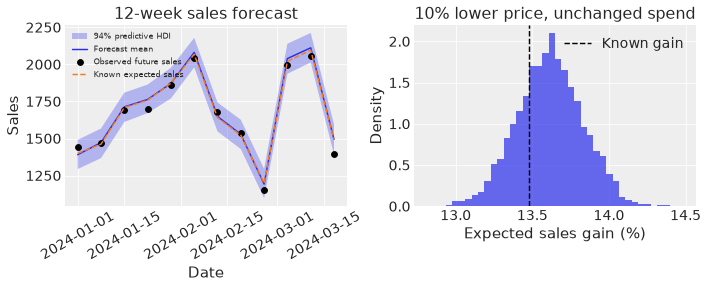

In [80]:
axes[1].set(
    title="10% lower price, unchanged spend",
    xlabel="Expected sales gain (%)",
    ylabel="Density",
)
axes[1].legend()
fig

Read the forecast errors and gain interval from the current output.
This scenario measures sales, not revenue or profit.
Buying behavior changes only through the specified elasticity.

Do not use this scenario as a pricing recommendation.
For observed data, a justified identification method is necessary for causal claims.

## 9. Set the joint media and price plan

Optimize the media effect multiplied by the price multiplier:

$$
\max_{\mathrm{spend},p}\;
\mathbb{E}_{\theta\mid y}\!\left[
    \sum_{t,c}\beta_cf_c(\mathrm{spend}_{c,t})M_t(p_t;\theta)
\right],\qquad
\sum_{t,c}\mathrm{spend}_{c,t}\le B.
$$

The selected term is `media_at_reference * market_multiplier`.
It measures the expected sales removed by zero spend at the same price.
It excludes the baseline.

The objective is not total sales, revenue, or profit.
It adds no cost assumptions or observed target.

Use this planning policy:

- Plan eight weeks.
- Add seven tail weeks with zero spend.
- Set the tail price to 10.
- Keep weekly spend constant for each channel during the plan.
- Select one price for all planned weeks.
- Use a maximum media budget, not a fixed spend total.
- Bound channel spend by its training maximum.
- Bound planned price by the observed training range.
- Start the two plans without training history.

The tail scores all carryover from the planned spend.
The same tail and history policy apply to the two plans.

Set the planned dates and tail dates.
Only the first eight weeks contain decisions.

In [81]:
plan_weeks = 8
carryover_weeks = l_max - 1
planning_dates = pd.date_range(
    start=train["date"].values[-1], periods=1 + plan_weeks, freq="W-MON"
)[1:]

In [82]:
tail_dates = pd.date_range(
    start=planning_dates[-1], periods=1 + carryover_weeks, freq="W-MON"
)[1:]

Use historical average weekly spend for the initial plan.
Set the maximum budget from eight weeks of this spend.
The budget uses original currency units.

In [83]:
weekly_spend = train["spend"].mean("date")
budget = float((weekly_spend * channel_scale).sum()) * plan_weeks
max_spend = train["spend"].max("date")
min_price = float(train["price"].min())
max_price = float(train["price"].max())

Make the fixed tail spend.
Keep the two channel labels and the tail dates.

In [84]:
tail_spend = xr.zeros_like(weekly_spend.expand_dims(date=tail_dates))
tail_spend = tail_spend.transpose("date", "channel")

Make the fixed tail price.
Put the tail inputs in one dataset.
The tail is not a decision variable.

In [85]:
tail_price = xr.DataArray(
    np.full(carryover_weeks, price_reference),
    dims="date",
    coords={"date": tail_dates},
)
fixed_tail = xr.Dataset({"spend": tail_spend, "price": tail_price})

In [86]:
print(f"Maximum media budget: {budget:.2f}")
print(f"Planned price range: {min_price:.2f} to {max_price:.2f}")
print(f"Tail price: {price_reference:.2f}")

Maximum media budget: 588.92
Planned price range: 8.01 to 11.99
Tail price: 10.00


### Write the objective and constraints

`u` holds symbolic decisions for the planned weeks.
`evaluate(u)` includes the fixed tail and paired posterior draws.
The posterior draw dimension is `sample`.

Sum the media effect over dates and channels.
Average it over posterior draws.
Convert the result to sales units.

In [87]:
from collections.abc import Mapping
from typing import Any

from pymc_marketing.experimental.terms import Problem

In [88]:
def expected_media_effect(evaluate: Any, u: Mapping[str, Any]) -> Any:
    """Return the posterior mean media effect in sales units."""
    effect = evaluate(u)["media_effect"] * target_scale
    return effect.sum("date").sum("channel").mean("sample")

Return budget minus planned spend.
For an `ineq` constraint, this value must be nonnegative.
Spend can be less than the maximum budget.

In [89]:
def remaining_budget(evaluate: Any, u: Mapping[str, Any]) -> Any:
    """Return the unspent media budget in currency units."""
    spend = u["spend"] * evaluate.constant(channel_scale)
    return evaluate.parameter("budget") - spend.sum("date").sum("channel")

Tie each planned week's channel spend to the first week.
The fixed tail stays outside this equality constraint.

In [90]:
def same_weekly_spend(evaluate: Any, u: Mapping[str, Any]) -> Any:
    """Keep channel spend constant during the planned weeks."""
    return u["spend"] - u["spend"].isel(date=0)

Tie each planned price to the first week.
The fixed tail keeps its reference price.

In [91]:
def same_weekly_price(evaluate: Any, u: Mapping[str, Any]) -> Any:
    """Keep price constant during the planned weeks."""
    return u["price"] - u["price"].isel(date=0)

Register the budget inequality and weekly equality constraints.
Keep the spend and price bounds separate.

In [92]:
plan_constraints = [
    {"type": "ineq", "fun": remaining_budget},
    {"type": "eq", "fun": same_weekly_spend},
    {"type": "eq", "fun": same_weekly_price},
]
decision_bounds = {"spend": (0.0, max_spend), "price": (min_price, max_price)}

Select the media effect multiplied by the price multiplier.
`Problem` infers the spend and price inputs from this term.
It compiles the fitted graph and callbacks before solving.

Do not supply training history.
The two plans start with zero earlier media carryover.

In [93]:
selected_terms = {"media_effect": media_at_reference * market_multiplier}
problem = Problem(
    model=gam,
    terms=selected_terms,
    dates=planning_dates,
    objective=expected_media_effect,
    bounds=decision_bounds,
    constraints=plan_constraints,
    parameters={"budget": budget},
    carryover=fixed_tail,
)

Show the decision template.
Only the eight planned weeks appear here.
Making a `Problem` does not solve it.

In [94]:
problem.decisions

<xarray.Dataset> Size: 272B
Dimensions:  (date: 8, channel: 2)
Coordinates:
  * date     (date) datetime64[us] 64B 2024-01-01 2024-01-08 ... 2024-02-19
  * channel  (channel) <U2 16B 'x1' 'x2'
Data variables:
    price    (date) float64 64B nan nan nan nan nan nan nan nan
    spend    (date, channel) float64 128B nan nan nan nan ... nan nan nan nan

## 10. Evaluate the plans

Make the initial plan from historical average spend.
Use the reference price for each planned week.

In [95]:
initial_plan = problem.decisions.copy()
initial_plan["spend"] = weekly_spend.broadcast_like(problem.decisions["spend"])
initial_plan["price"] = xr.full_like(problem.decisions["price"], price_reference)

Evaluate this plan before solving.
`evaluate` scores a concrete plan without changing it.

In [96]:
initial_draws = problem.evaluate(initial_plan)

Run the optimizer with the initial plan as `x0`.
`solve` is the explicit optimizer call.

In [97]:
optimized_plan = problem.solve(x0=initial_plan)

### Make sure the solution is feasible

Make sure the solver succeeds.
Make sure the solution is feasible.
Then score the optimized allocation on the same posterior draws.

In [98]:
if not (optimized_plan.scipy.success and optimized_plan.feasible):
    raise RuntimeError(f"Optimization failed: {optimized_plan.scipy.message}")
allocation = optimized_plan.allocation
optimized_draws = problem.evaluate(allocation)

Make sure total spend stays within the maximum budget.
Use currency units for this comparison.

In [99]:
optimized_spend = allocation["spend"] * channel_scale
budget_slack = budget - float(optimized_spend.sum())
np.testing.assert_array_less(-1e-6, budget_slack)

Make sure weekly spend and price stay constant during the plan.

In [100]:
for name in ("spend", "price"):
    planned_values = allocation[name]
    np.testing.assert_allclose(
        planned_values,
        planned_values.isel(date=0).broadcast_like(planned_values),
        atol=1e-7,
        rtol=1e-8,
    )

Show solver success, feasibility, and the remaining budget.
Read the maximum bound and constraint violations.
These violations use the model scales.

In [101]:
solver_checks = {
    "SciPy success": optimized_plan.scipy.success,
    "Independent feasibility": optimized_plan.feasible,
    "Remaining budget (currency)": float(optimized_plan.constraints[0]),
    "Maximum scaled bound violation": optimized_plan.max_bound_violation,
    "Maximum scaled constraint violation": optimized_plan.max_constraint_violation,
}
pd.Series(solver_checks, name="Solver diagnostics").to_frame()

,Solver diagnostics
SciPy success,True
Independent feasibility,True
Remaining budget (currency),-0.0
Maximum scaled bound violation,0.0
Maximum scaled constraint violation,0.0


Show the weekly decisions in original units.
Use one row for each channel and one row for price.

In [102]:
decision_labels = [f"Weekly spend: {channel}" for channel in channels]
initial_week = pd.Series((weekly_spend * channel_scale).values, index=decision_labels)
initial_week["Price per unit"] = price_reference

In [103]:
optimized_week = pd.Series(optimized_spend.isel(date=0).values, index=decision_labels)
optimized_week["Price per unit"] = float(allocation["price"].isel(date=0))
weekly_decisions = pd.DataFrame(
    {"Initial plan": initial_week, "Optimized plan": optimized_week}
)
weekly_decisions.round(3)

,Initial plan,Optimized plan
Weekly spend: x1,40.606,48.609
Weekly spend: x2,33.009,25.006
Price per unit,10.000,8.006


### Compare the paired media effects

Use the same posterior draws, fixed tail, and history policy for the two plans.
Sum the media effects over all scored dates and channels.
Make sure the optimized mean equals the solver objective.

In [104]:
initial_media_effect = initial_draws["media_effect"] * target_scale
optimized_media_effect = optimized_draws["media_effect"] * target_scale
initial_effect = initial_media_effect.sum(("date", "channel"))
optimized_effect = optimized_media_effect.sum(("date", "channel"))

In [105]:
np.testing.assert_allclose(
    float(optimized_effect.mean()), optimized_plan.objective, rtol=1e-10
)

### Compare with independent posterior predictions

Append the fixed tail to each concrete plan.
Use posterior prediction without training history.
This path is separate from `Problem.evaluate`.

In [106]:
full_plans = {
    "Initial plan": xr.concat([initial_plan, fixed_tail], dim="date"),
    "Optimized plan": xr.concat([allocation, fixed_tail], dim="date"),
}
effect_names = ["sales_response", "media_at_reference", "market_multiplier"]

In [107]:
plan_predictions = {}
for label, full_plan in full_plans.items():
    plan_predictions[label] = gam.sample_posterior_predictive(
        full_plan,
        var_names=effect_names,
        include_last_observations=False,
        random_seed=71,
        progressbar=False,
    )

Sampling: []


Sampling: []


Set media spend to zero for each plan.
Keep that plan's price, including the fixed tail price.

In [108]:
zero_media_inputs = {}
for label, full_plan in full_plans.items():
    zero_media_inputs[label] = full_plan.assign(spend=xr.zeros_like(full_plan["spend"]))

In [109]:
zero_media_predictions = {}
for label, full_plan in zero_media_inputs.items():
    zero_media_predictions[label] = gam.sample_posterior_predictive(
        full_plan,
        var_names=["sales_response"],
        include_last_observations=False,
        random_seed=71,
        progressbar=False,
    )

Sampling: []


Sampling: []


Calculate media effects from the independent predictions.
Convert them to sales units.

In [110]:
predicted_media_effects = {}
for label, prediction in plan_predictions.items():
    predicted_media_effects[label] = (
        prediction["media_at_reference"]
        * prediction["market_multiplier"]
        * target_scale
    )

Align the posterior dimensions with the optimization output.
Keep the same paired draw order.

In [111]:
evaluated_effects = {
    "Initial plan": initial_media_effect,
    "Optimized plan": optimized_media_effect,
}
aligned_effects = {}
for label, effect in evaluated_effects.items():
    stacked = predicted_media_effects[label].stack(sample=("chain", "draw"))
    aligned_effects[label] = stacked.transpose(*effect.dims)

For each plan, make sure the two evaluation paths agree.
Compare every channel, date, and posterior draw.

In [112]:
for label, effect in evaluated_effects.items():
    np.testing.assert_allclose(aligned_effects[label], effect, rtol=1e-10, atol=1e-10)

Subtract zero-media expected sales from each plan's expected sales.
The same-price subtraction removes the baseline.

In [113]:
response_differences = {}
for label, prediction in plan_predictions.items():
    no_media = zero_media_predictions[label]
    response_differences[label] = (
        prediction["sales_response"] - no_media["sales_response"]
    ) * target_scale

Make sure each difference equals the sum of media effects.
This assertion excludes the baseline in every draw and week.

In [114]:
for label, difference in response_differences.items():
    np.testing.assert_allclose(
        difference,
        predicted_media_effects[label].sum("channel"),
        rtol=1e-10,
        atol=1e-10,
    )
print("Independent predictions agree. The media effects exclude the baseline.")

Independent predictions agree. The media effects exclude the baseline.


### Read the plan comparison

Show the posterior mean total media effect for each plan.
The total includes the fixed carryover tail.

In [115]:
comparison = pd.DataFrame(
    {
        "Initial plan": [float(initial_effect.mean())],
        "Optimized plan": [float(optimized_effect.mean())],
    },
    index=["Mean total media effect (sales)"],
)
comparison.round(2)

,Initial plan,Optimized plan
Mean total media effect (sales),5503.02,7193.49


Calculate the media effect gain from paired draws.
Measure the percentage against the initial plan's mean effect.

In [116]:
media_gain = optimized_effect - initial_effect
mean_media_gain = float(media_gain.mean())
relative_media_gain = mean_media_gain / float(initial_effect.mean())
gain_lower = float(media_gain.quantile(0.03))
gain_upper = float(media_gain.quantile(0.97))
gain_probability = float((media_gain > 0).mean())

In [117]:
gain_summary = pd.Series(
    {
        "Mean media effect gain (sales)": mean_media_gain,
        "Gain against initial mean effect (%)": 100 * relative_media_gain,
        "Gain 3% (sales)": gain_lower,
        "Gain 97% (sales)": gain_upper,
        "P(media effect gain > 0)": gain_probability,
    },
    name="Paired posterior comparison",
)
gain_summary.round(3).to_frame()

,Paired posterior comparison
Mean media effect gain (sales),1690.473
Gain against initial mean effect (%),30.719
Gain 3% (sales),1583.925
Gain 97% (sales),1798.653
P(media effect gain > 0),1.000


Read the optimized price and remaining budget from the current tables.
Compare them with the price bounds and budget limit.
Spend can be less than the maximum budget.

A negative price elasticity rewards lower prices for this objective.
There is no revenue or margin term.
The gain interval describes expected media effects, not noisy realized sales.

The solver gives a local constrained solution.
It does not establish a global optimum.
Do not treat it as a pricing recommendation.

For observed data, justified price bounds and a causal identification method are necessary.
The simulated example does not establish causal effects for observed data.

## Summary

The media components and labeled inputs stay unchanged.
The mean multiplies a positive additive response by a price multiplier.
The likelihood is a separate choice.

The assertions compare the graph with NumPy at the known parameters.
They also test reference-price identity, component reconciliation, forecast elasticity, and the optimization objective.
They do not remove posterior uncertainty or establish causal identification.

`Problem` defines the decisions, bounds, constraints, and fixed tail.
`evaluate` scores an explicit plan.
`solve` runs the optimizer.

The objective includes media effects at the selected price.
It excludes the baseline.
`sales` is the only observed target.

In [118]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,pytensor,nutpie

Last updated: Sat, 17 Oct 2026

Python implementation: CPython
Python version       : 3.13.9
IPython version      : 9.15.0

pymc_marketing: 1.2.0
pytensor      : 3.3.2
nutpie        : 0.16.11

IPython       : 9.15.0
arviz         : 1.2.0
matplotlib    : 3.11.1
numpy         : 2.4.6
pandas        : 3.0.5
pymc          : 6.3.2
pymc_extras   : 0.15.1
pymc_marketing: 1.2.0
pytensor      : 3.3.2
xarray        : 2026.4.0

Watermark: 2.6.0

